# Student 5: 2D Fourier Transform & Image Filtering


---
### Project Objectives

- Load an image and convert it to grayscale.
- Compute and display the 2D Fourier Transform.
- Apply an Ideal Circular Low-Pass Filter.
- Apply an Ideal Circular High-Pass Filter.
- Compare the results of both filters.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from google.colab import files

## 3. Loading the Image

In [2]:
uploaded = files.upload()

image_name = next(iter(uploaded))

image_array = np.frombuffer(uploaded[image_name], np.uint8)

image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

if image is None:
    raise ValueError("Image could not be loaded.")

print("Image loaded successfully!")
print("Image dimensions:", image.shape)

Saving cameraman.tif to cameraman.tif
Image loaded successfully!
Image dimensions: (256, 256, 3)


## 4. Grayscale Conversion

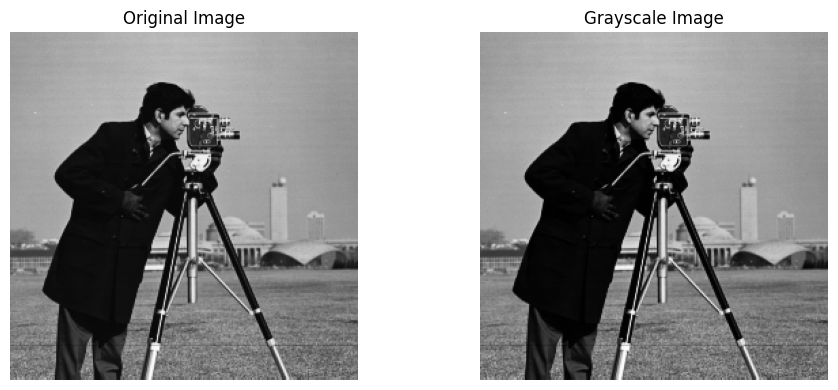

Grayscale image dimensions: (256, 256)


In [3]:
# Convert the image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Display the original and grayscale images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Grayscale image dimensions:", gray_image.shape)

## 5. 2D Fourier Transform

In [4]:
# Apply the 2D Fourier Transform
f_transform = np.fft.fft2(gray_image)

# Move the zero-frequency component to the center
f_shift = np.fft.fftshift(f_transform)

print("Fourier Transform completed successfully!")
print("Transform dimensions:", f_shift.shape)

Fourier Transform completed successfully!
Transform dimensions: (256, 256)


### 5.1 Fourier Magnitude Spectrum

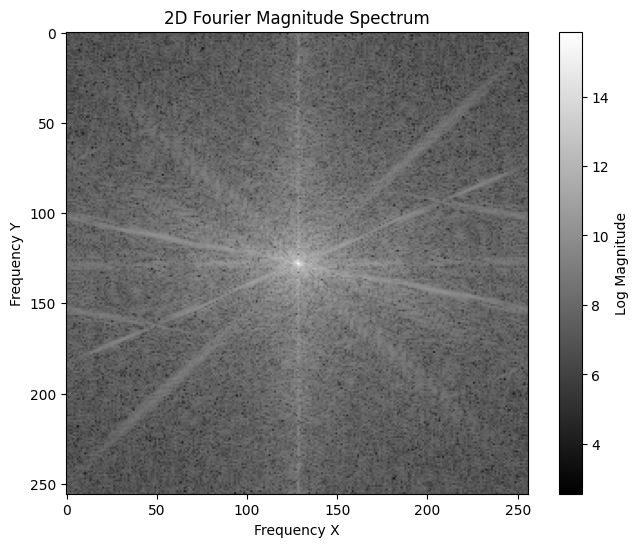

In [5]:
# Calculate the magnitude spectrum
magnitude_spectrum = np.abs(f_shift)

# Apply logarithmic scaling
magnitude_spectrum_log = np.log1p(magnitude_spectrum)

# Display the spectrum
plt.figure(figsize=(8, 6))

plt.imshow(magnitude_spectrum_log, cmap='gray')
plt.title("2D Fourier Magnitude Spectrum")
plt.xlabel("Frequency X")
plt.ylabel("Frequency Y")
plt.colorbar(label="Log Magnitude")

plt.show()

## 6. Ideal Circular Low-Pass Filter

A Low-Pass Filter allows low spatial frequencies to pass while blocking high spatial frequencies.

It preserves the general structure of the image and reduces fine details and sharp edges.

In this experiment, an ideal circular mask is applied to the Fourier Transform.

###6.2 Creating the Circular Mask

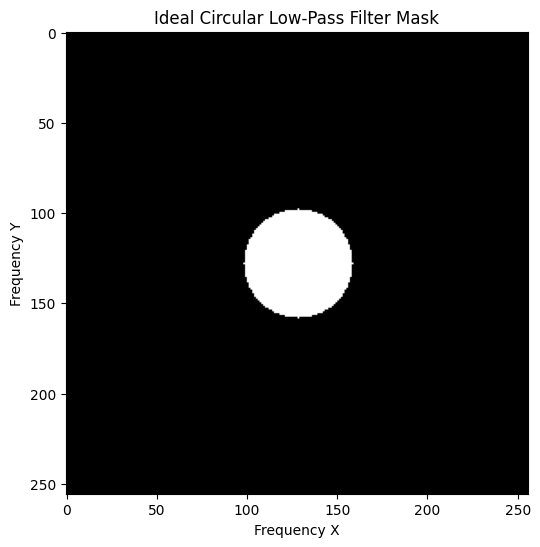

In [6]:
# Create an ideal circular Low-Pass Filter

rows, cols = gray_image.shape

center_row = rows // 2
center_col = cols // 2

cutoff = 30

y, x = np.ogrid[:rows, :cols]

distance = np.sqrt(
    (x - center_col)**2 + (y - center_row)**2
)

low_pass_mask = (distance <= cutoff).astype(np.uint8)

# Display the filter mask
plt.figure(figsize=(6, 6))
plt.imshow(low_pass_mask, cmap='gray')
plt.title("Ideal Circular Low-Pass Filter Mask")
plt.xlabel("Frequency X")
plt.ylabel("Frequency Y")
plt.show()

###6.3 Applying the Low-Pass Filter

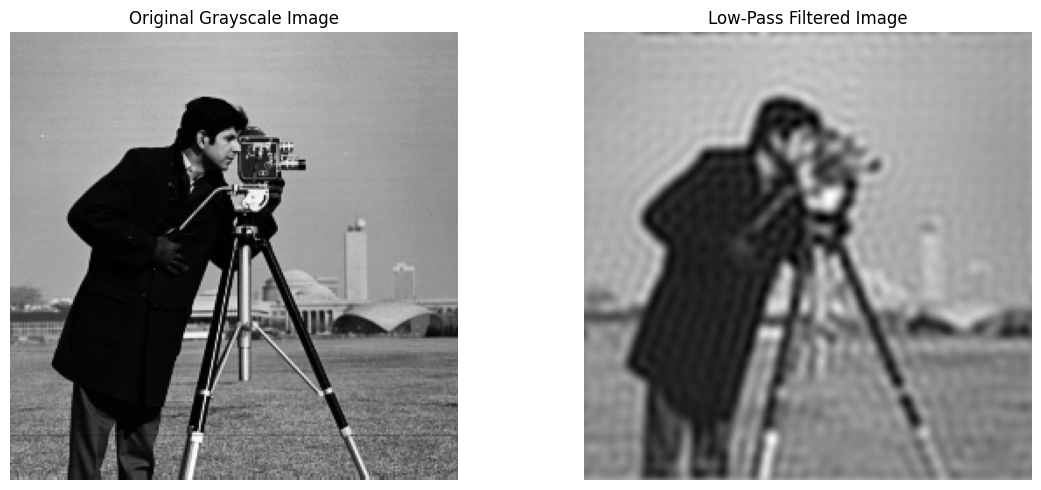

In [7]:
# Apply the Low-Pass Filter

low_pass_result = f_shift * low_pass_mask

# Convert back to the spatial domain
low_pass_image = np.fft.ifft2(
    np.fft.ifftshift(low_pass_result)
)

low_pass_image = np.real(low_pass_image)

# Display the original and filtered images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(low_pass_image, cmap='gray')
plt.title("Low-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Ideal Circular High-Pass Filter

A High-Pass Filter allows high spatial frequencies to pass while removing low spatial frequencies.

It reduces smooth intensity variations and preserves fine details and edges.

In this section, an ideal circular High-Pass mask is applied to the Fourier Transform.

###7.2 Creating the High-Pass Mask

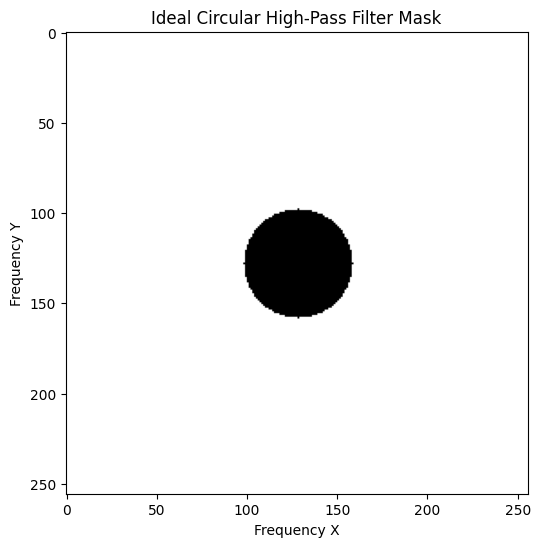

In [8]:
# Create an ideal circular High-Pass Filter

high_pass_mask = 1 - low_pass_mask

plt.figure(figsize=(6, 6))
plt.imshow(high_pass_mask, cmap='gray')
plt.title("Ideal Circular High-Pass Filter Mask")
plt.xlabel("Frequency X")
plt.ylabel("Frequency Y")
plt.show()

###7.3 Applying the High-Pass Filter

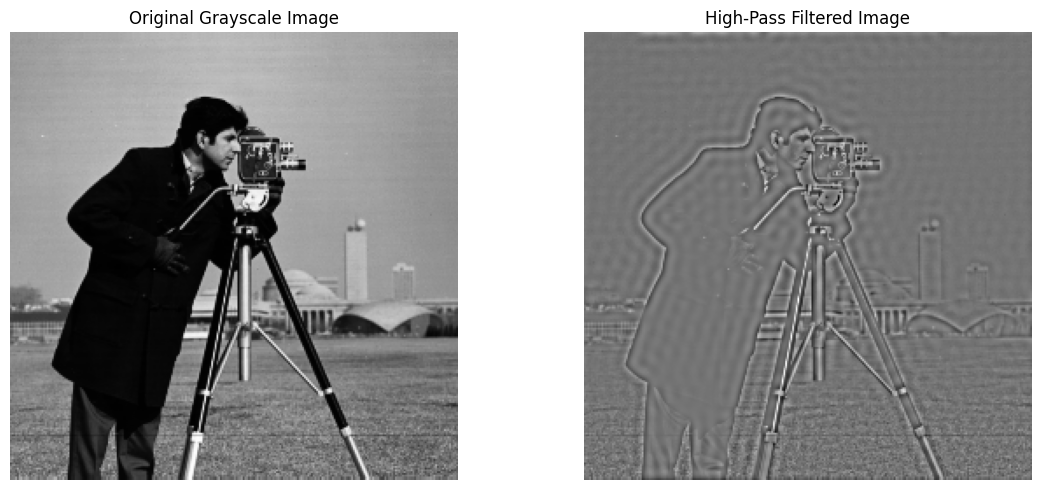

In [9]:
# Apply the High-Pass Filter

high_pass_result = f_shift * high_pass_mask

# Convert back to the spatial domain
high_pass_image = np.fft.ifft2(
    np.fft.ifftshift(high_pass_result)
)

high_pass_image = np.real(high_pass_image)

# Display the original and filtered images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(high_pass_image, cmap='gray')
plt.title("High-Pass Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## 8. Comparison of Filtering Results
The comparison shows how each filter affects the spatial details and frequency components of the image.

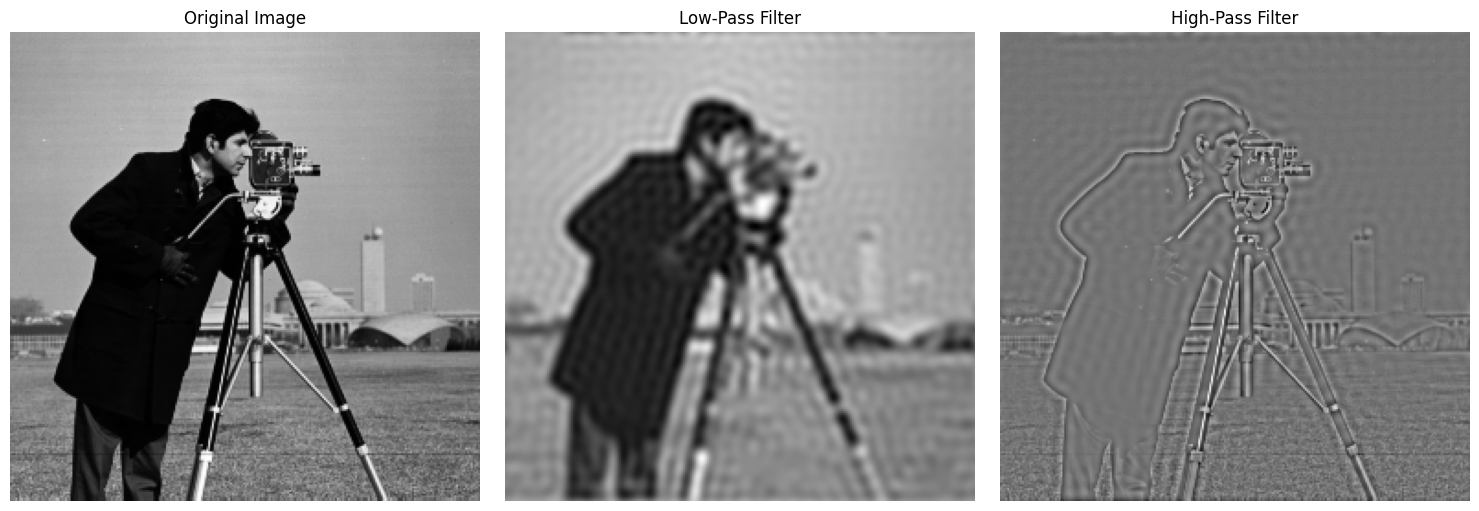

In [10]:
# Normalize the High-Pass result for better visualization
high_pass_display = cv2.normalize(
    high_pass_image, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(low_pass_image, cmap='gray')
plt.title("Low-Pass Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(high_pass_display, cmap='gray')
plt.title("High-Pass Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

The Low-Pass filter produces a smoother image by reducing high-frequency details.

In contrast, the High-Pass filter highlights edges and fine details by removing low-frequency components.

The results show how frequency-domain filtering changes the visual properties of an image.